In [4]:
data = np.load('mnist.npz')

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import random
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from PIL import Image, ImageOps

In [12]:
# Load dataset from local file
data = np.load('mnist.npz')
x_train, y_train = data['x_train'], data['y_train']
x_test, y_test = data['x_test'], data['y_test']

print(f"x_train shape: {x_train.shape}")
print(f"x_test shape: {x_test.shape}")

x_train shape: (60000, 28, 28)
x_test shape: (10000, 28, 28)


In [13]:
# Load dataset from local file
data = np.load('mnist.npz')
x_train, y_train = data['x_train'], data['y_train']
x_test, y_test = data['x_test'], data['y_test']

print(f"x_train shape: {x_train.shape}")
print(f"x_test shape: {x_test.shape}")

x_train shape: (60000, 28, 28)
x_test shape: (10000, 28, 28)


In [14]:
# Reshape and Normalize to 0-1
x_train = x_train.reshape(-1, 28, 28, 1) / 255.0
x_test = x_test.reshape(-1, 28, 28, 1) / 255.0

print(f"After preprocessing: {x_test.shape}")

After preprocessing: (10000, 28, 28, 1)


In [15]:
# Build CNN Model
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

# Train - 2 epochs is enough for the task
model.fit(x_train, y_train, epochs=2, validation_split=0.1, verbose=1)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/2
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 23s 13ms/step - accuracy: 0.9481 - loss: 0.1763 - val_accuracy: 0.9807 - val_loss: 0.0714
Epoch 2/2
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.9798 - loss: 0.0645 - val_accuracy: 0.9842 - val_loss: 0.0584


----- Task 1: Deep Prediction Analysis -----


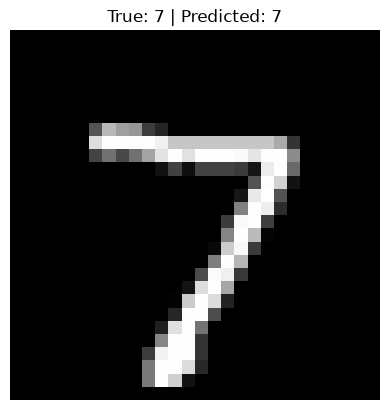

Sample 0: True=7, Predicted=7, Correct=True



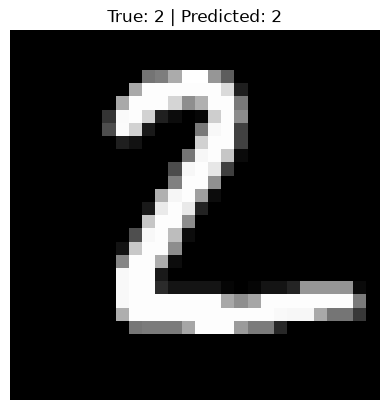

Sample 1: True=2, Predicted=2, Correct=True



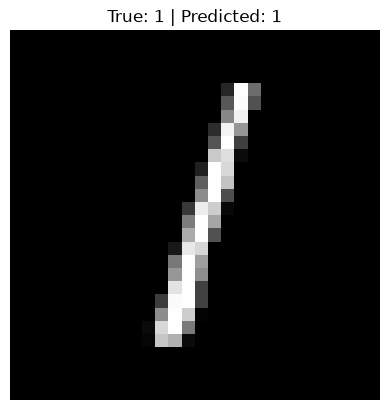

Sample 2: True=1, Predicted=1, Correct=True



In [16]:
# TASK 1: Show 3 samples with True and Predicted Label
print("----- Task 1: Deep Prediction Analysis -----")

indices = [0, 1, 2]  # you can change to random.sample(range(10000), 3)

for i in indices:
    img = x_test[i]
    true_label = y_test[i]
    
    pred = model.predict(img.reshape(1, 28, 28, 1), verbose=0)
    pred_label = np.argmax(pred)
    
    plt.imshow(img.reshape(28,28), cmap='gray')
    plt.title(f"True: {true_label} | Predicted: {pred_label}")
    plt.axis('off')
    plt.show()
    
    print(f"Sample {i}: True={true_label}, Predicted={pred_label}, Correct={true_label==pred_label}\n")

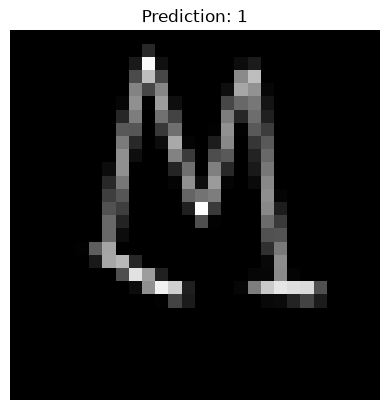

Predicted as: 1


In [19]:
# TASK 2 - FINAL FOR PNG
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

image_path = 'paint to test.png'  # ده اسم صورتك

img = Image.open(image_path).convert("L")
img = ImageOps.invert(img)
img = img.resize((28, 28))
img_array = np.array(img) / 255.0
img_array = img_array.reshape(1, 28, 28, 1)

pred = model.predict(img_array, verbose=0)
final_pred = np.argmax(pred)

plt.imshow(img_array.reshape(28,28), cmap='gray')
plt.title(f"Prediction: {final_pred}")
plt.axis('off')
plt.show()

print(f"Predicted as: {final_pred}")